# Mini-projekt — wpływ Dropout na skuteczność klasyfikacji MLP

**Problem:** klasyfikacja binarna na zbiorze Breast Cancer Wisconsin (`sklearn.datasets.load_breast_cancer`).

**Hipoteza (UGŁ_U01):** zastosowanie Dropout (p = 0,2) w sieci MLP zwiększy średni ROC-AUC na zbiorze testowym w porównaniu z tą samą architekturą bez Dropout.

**Modele:** regresja logistyczna (model referencyjny), MLP bez Dropout oraz MLP z Dropout (p = 0,2).

**Metodyka:** trzy niezależne podziały stratyfikowane (60% trening / 20% walidacja / 20% test), identyczne podziały dla wszystkich modeli w danym powtórzeniu; standaryzacja dopasowana tylko do treningu; stała architektura, liczba epok i optymalizator; metryki ROC-AUC, accuracy i F1. Zbiór walidacyjny służy wyłącznie do wyboru progu klasyfikacji w dodatkowym eksperymencie. Zbiór testowy służy wyłącznie do końcowej oceny.

In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import sklearn

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Urządzenie: CPU")

torch.set_num_threads(1)
ZIARNA = [11, 42, 73]
EPOKI = 100
BATCH_SIZE = 64
LR = 0.003

Python: 3.13.16
PyTorch: 2.11.0+cpu
scikit-learn: 1.6.1
NumPy: 2.1.3
pandas: 2.2.3
Urządzenie: CPU


## 1. Dane i podziały

In [2]:
dane = load_breast_cancer()
X = dane.data.astype(np.float32)
y = dane.target.astype(np.int64)
print("Liczba obserwacji:", len(y))
print("Liczba cech:", X.shape[1])
print("Liczebności klas:", dict(zip(*np.unique(y, return_counts=True))))

Liczba obserwacji: 569
Liczba cech: 30
Liczebności klas: {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}


## 2. Modele i trening

In [3]:
class SiecMLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(30, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)


def trenuj_mlp(X_train, y_train, dropout, ziarno):
    torch.manual_seed(ziarno)
    model = SiecMLP(dropout)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    strata = nn.BCEWithLogitsLoss()
    ds = torch.utils.data.TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1),
    )
    generator = torch.Generator().manual_seed(ziarno)
    loader = torch.utils.data.DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
    for _ in range(EPOKI):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = strata(model(xb), yb)
            loss.backward()
            opt.step()
    return model


def pred_mlp(model, X_data):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X_data, dtype=torch.float32))
        return torch.sigmoid(logits).numpy().reshape(-1)


def metryki(y_true, p, prog=0.5):
    yp = (p >= prog).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, p),
            "Accuracy": accuracy_score(y_true, yp),
            "F1": f1_score(y_true, yp)}

## 3. Porównanie w trzech powtórzeniach

In [4]:
wyniki = []
proby = {}

for ziarno in ZIARNA:
    X_trv, X_test, y_trv, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=ziarno
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_trv, y_trv, test_size=0.25, stratify=y_trv, random_state=ziarno
    )
    scaler = StandardScaler().fit(X_train)
    xt = scaler.transform(X_train).astype(np.float32)
    xv = scaler.transform(X_val).astype(np.float32)
    xe = scaler.transform(X_test).astype(np.float32)

    reg = LogisticRegression(max_iter=1000, random_state=ziarno).fit(xt, y_train)
    p_reg = reg.predict_proba(xe)[:, 1]
    mlp0 = trenuj_mlp(xt, y_train, dropout=0.0, ziarno=ziarno)
    mlp02 = trenuj_mlp(xt, y_train, dropout=0.2, ziarno=ziarno)
    p_mlp0 = pred_mlp(mlp0, xe)
    p_mlp02 = pred_mlp(mlp02, xe)

    for nazwa, p in [("Regresja logistyczna", p_reg), ("MLP bez Dropout", p_mlp0), ("MLP Dropout 0.2", p_mlp02)]:
        wyniki.append({"Seed": ziarno, "Model": nazwa, **metryki(y_test, p)})

    p_val = pred_mlp(mlp02, xv)
    progi = np.arange(0.25, 0.751, 0.05)
    prog_val = float(progi[np.argmax([f1_score(y_val, p_val >= t) for t in progi])])
    proby[ziarno] = {"y_test": y_test, "prob": {
        "Regresja logistyczna": p_reg, "MLP bez Dropout": p_mlp0, "MLP Dropout 0.2": p_mlp02},
        "prog_val": prog_val,
        "F1_0.5": f1_score(y_test, p_mlp02 >= 0.5),
        "F1_po_walidacji": f1_score(y_test, p_mlp02 >= prog_val)}

wyniki_df = pd.DataFrame(wyniki)
display(wyniki_df.round(4))

,Seed,Model,ROC-AUC,Accuracy,F1
0,11,Regresja logistyczna,0.9848,0.9561,0.9660
1,11,MLP bez Dropout,0.9808,0.9561,0.9664
2,11,MLP Dropout 0.2,0.9803,0.9386,0.9524
3,42,Regresja logistyczna,0.9950,0.9825,0.9861
4,42,MLP bez Dropout,0.9937,0.9561,0.9645
5,42,MLP Dropout 0.2,0.9897,0.9561,0.9650
6,73,Regresja logistyczna,0.9974,0.9825,0.9863
7,73,MLP bez Dropout,1.0000,0.9825,0.9859
8,73,MLP Dropout 0.2,1.0000,0.9912,0.9930


## 4. Wyniki zbiorcze i hipoteza

In [5]:
podsumowanie = wyniki_df.groupby("Model", sort=False)[["ROC-AUC", "Accuracy", "F1"]].agg(["mean", "std"])
display(podsumowanie.round(4))

srednia_auc = wyniki_df.groupby("Model")["ROC-AUC"].mean()
delta = float(srednia_auc["MLP Dropout 0.2"] - srednia_auc["MLP bez Dropout"])
print(f"Różnica średniego ROC-AUC (MLP Dropout - MLP bez Dropout): {delta:+.4f}")
if delta > 0:
    print("Hipoteza: zgodna z zaobserwowanym kierunkiem średniej różnicy; potrzebna ostrożność przy n=3.")
elif delta < 0:
    print("Hipoteza: niepotwierdzona w tych trzech powtórzeniach.")
else:
    print("Hipoteza: brak różnicy średniego ROC-AUC w tych trzech powtórzeniach.")

ROC-AUC         Accuracy              F1        
                        mean     std     mean     std    mean     std
Model                                                                
Regresja logistyczna  0.9924  0.0067   0.9737  0.0152  0.9795  0.0117
MLP bez Dropout       0.9915  0.0098   0.9649  0.0152  0.9723  0.0118
MLP Dropout 0.2       0.9900  0.0098   0.9620  0.0268  0.9701  0.0208

Różnica średniego ROC-AUC (MLP Dropout - MLP bez Dropout): -0.0015
Hipoteza: niepotwierdzona w tych trzech powtórzeniach.


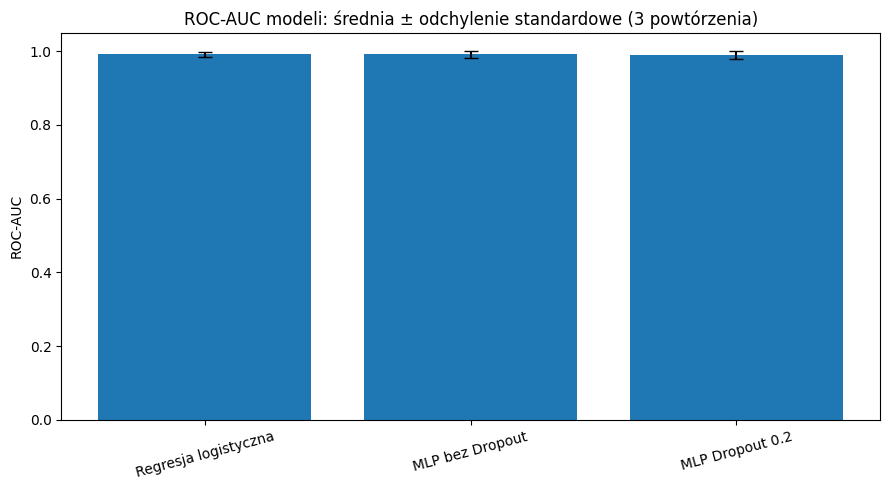

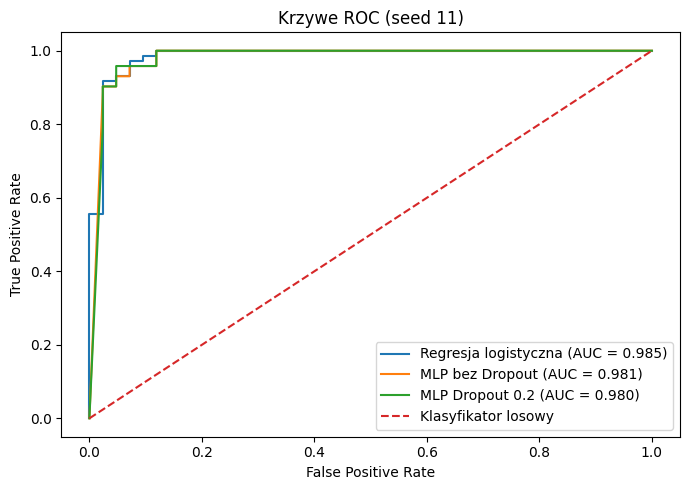

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
modele = ["Regresja logistyczna", "MLP bez Dropout", "MLP Dropout 0.2"]
srednie = [wyniki_df.loc[wyniki_df.Model == m, "ROC-AUC"].mean() for m in modele]
odchylenia = [wyniki_df.loc[wyniki_df.Model == m, "ROC-AUC"].std(ddof=1) for m in modele]
ax.bar(modele, srednie, yerr=odchylenia, capsize=5)
ax.set_title("ROC-AUC modeli: średnia ± odchylenie standardowe (3 powtórzenia)")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
pierwsza = proby[ZIARNA[0]]
for nazwa, p in pierwsza["prob"].items():
    fpr, tpr, _ = roc_curve(pierwsza["y_test"], p)
    ax.plot(fpr, tpr, label=f"{nazwa} (AUC = {roc_auc_score(pierwsza['y_test'], p):.3f})")
ax.plot([0, 1], [0, 1], "--", label="Klasyfikator losowy")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=f"Krzywe ROC (seed {ZIARNA[0]})")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Usprawnienie (UGŁ_U02) — dobór progu na zbiorze walidacyjnym

,Seed,Próg wybrany na walidacji,"F1 na teście, próg 0.5","F1 na teście, próg walidacyjny"
0,11,0.25,0.9524,0.9595
1,42,0.25,0.9650,0.9722
2,73,0.50,0.9930,0.9930


Średnia zmiana F1 po wyborze progu na walidacji: 0.0048


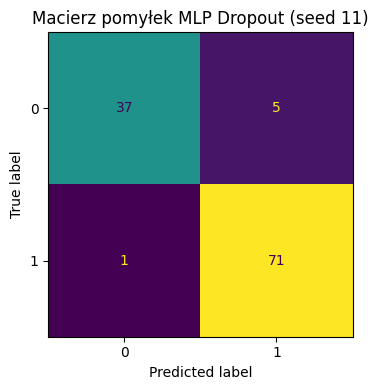

In [7]:
progi_df = pd.DataFrame([{"Seed": s,
    "Próg wybrany na walidacji": w["prog_val"],
    "F1 na teście, próg 0.5": w["F1_0.5"],
    "F1 na teście, próg walidacyjny": w["F1_po_walidacji"]}
    for s, w in proby.items()])
display(progi_df.round(4))
print("Średnia zmiana F1 po wyborze progu na walidacji:",
      round(float((progi_df["F1 na teście, próg walidacyjny"] - progi_df["F1 na teście, próg 0.5"]).mean()), 4))

p = pierwsza["prob"]["MLP Dropout 0.2"]
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(pierwsza["y_test"], p >= pierwsza["prog_val"])).plot(ax=ax, colorbar=False)
ax.set_title(f"Macierz pomyłek MLP Dropout (seed {ZIARNA[0]})")
plt.tight_layout()
plt.show()

## 6. Wnioski i ograniczenia

Eksperyment obejmuje mały zbiór 569 obserwacji oraz trzy losowe podziały danych. Odchylenie standardowe pomiędzy powtórzeniami opisuje zmienność uzyskanych wyników, ale trzy powtórzenia nie wystarczają do silnych wniosków statystycznych. Wyniki odnoszą się wyłącznie do badanej architektury, parametrów uczenia i zbioru danych.

## Bibliografia

1. Scikit-learn Developers, *Breast cancer Wisconsin (diagnostic) dataset*, dokumentacja `load_breast_cancer`.
2. Paszke P. i in. (2019), *PyTorch: An Imperative Style, High-Performance Deep Learning Library*, NeurIPS.
3. Srivastava N. i in. (2014), *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*, JMLR 15, 1929–1958.